# Prueba I – Fundamentos de Inteligencia Artificial

**Escuela Politécnica Nacional – Escuela de Formación de Tecnólogos**
Tecnología Superior en Desarrollo de Software
Profesor: Ing. Juan Carlos González MSc. – Período 2026-B


**Parte Práctoca:** 90 minutos
**Duración:** 90 minutos
**Peso:** 80% de la nota final de la Prueba I
**Temas:** regresión lineal y regresión logística con scikit-learn

| Campo | Completar |
|---|---|
| Nombre completo | Alejandro Aguirre |
| Fecha | 26/10/2026|

## Instrucciones

1. La prueba es **individual** y sin acceso a internet, inteligencia artificial, apuntes ni código de apoyo. Tampoco está permitido usar `help()`, `?` ni la documentación integrada. La única referencia permitida es la ficha que aparece más abajo.
2. Escriba su respuesta **únicamente** en las celdas marcadas con `# Criterio ...` o con **Respuesta:**. No modifique las celdas que generan los datos.
3. Use **exactamente** los nombres de variables que se piden en cada criterio. Si la variable no existe o tiene otro nombre, el criterio se califica como no cumplido.
4. Algunos pasos tienen a continuación una **celda de rescate**. Si no logra completar ese paso, quite los símbolos `#` de la celda de rescate y ejecútela: le entrega el resultado correcto para que pueda continuar con los demás criterios, pero el criterio de ese paso se califica como no cumplido.
5. Antes de entregar, ejecute **Reiniciar kernel y ejecutar todo** (Restart & Run All) y verifique que el notebook corre de principio a fin sin errores. Se califica el resultado de esa ejecución.
6. Guarde el archivo como `Apellido_Nombre_PruebaI.ipynb` y súbalo al aula virtual.

## Calificación

Cada criterio se califica como **cumple** o **no cumple**. Si cumple, recibe el porcentaje completo; si no cumple, recibe cero. No hay puntaje parcial dentro de un criterio.

| Ejercicio | Criterio | Peso |
|---|---|---|
| 1. Regresión lineal | L1 – Diagrama de dispersión | 3.5 % |
| | L2 – Coeficiente de correlación | 3.5 % |
| | L3 – División entrenamiento / prueba | 9 % |
| | L4 – Entrenamiento del modelo | 9 % |
| | L5 – Pendiente e intercepto | 9 % |
| | L6 – R² en el conjunto de prueba | 9 % |
| | L7 – Predicción para 150 usuarios | 3.5 % |
| | L8 – Pregunta sobre extrapolación | 3.5 % |
| 2. Regresión logística | G1 – División entrenamiento / prueba | 9 % |
| | G2 – Entrenamiento y predicción | 9 % |
| | G3 – Matriz de confusión | 9 % |
| | G4 – Probabilidades de abandono | 3.5 % |
| | G5 – AUC | 9 % |
| | G6 – Interpretación del AUC | 3.5 % |
| | G7 – Predicción para una estudiante nueva | 3.5 % |
| | G8 – Probabilidad de abandono de la estudiante nueva | 3.5 % |
| **Total** | | **100 %** |

La nota sobre 10 se obtiene dividiendo el porcentaje total para 10.

## Ficha de referencia (funciones permitidas)

Esta ficha solo indica nombres y parámetros. Usted decide qué datos pasar a cada función y en qué orden aplicarlas.

```
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
    train_test_split(X, y, test_size, random_state)
    # devuelve X_train, X_test, y_train, y_test

from sklearn.linear_model import LinearRegression, LogisticRegression
    LinearRegression()
    LogisticRegression(random_state, max_iter)
    modelo.fit(X, y)
    modelo.predict(X)
    modelo.predict_proba(X)      # columna 0: clase 0, columna 1: clase 1
    modelo.score(X, y)
    modelo.coef_
    modelo.intercept_

from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve
    confusion_matrix(y_true, y_pred)        # filas: valor real, columnas: predicción
    accuracy_score(y_true, y_pred)
    roc_auc_score(y_true, y_probabilidades)

pandas
    df["columna"]          df[["col1", "col2"]]          df.drop(columns="columna")
    df.head()              df.shape                      df["columna"].mean()
    df["col1"].corr(df["col2"])
    pd.DataFrame([[valor1, valor2]], columns=["col1", "col2"])

matplotlib
    plt.scatter(x, y)      plt.xlabel(texto)    plt.ylabel(texto)    plt.title(texto)    plt.show()

numpy
    np.array([[valor]])
```

In [1]:
# Celda de importaciones. Ejecútela primero y no la modifique.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve

---
# Ejercicio 1. Regresión lineal (50 %)

El equipo de backend de una aplicación quiere estimar el **tiempo de respuesta** de su API (en milisegundos) a partir del **número de usuarios conectados al mismo tiempo**. Se registraron 120 mediciones en el ambiente de pruebas. Cada fila es una medición:

| Columna | Significado |
|---|---|
| `usuarios` | Usuarios conectados al mismo tiempo |
| `tiempo_ms` | Tiempo de respuesta promedio de la API, en milisegundos |

In [2]:
# Generación de datos. NO MODIFICAR.
rng = np.random.default_rng(2026)
usuarios = rng.integers(10, 201, size=120)
tiempo = 80 + 2.5 * usuarios + rng.normal(0, 40, size=120)
datos_api = pd.DataFrame({"usuarios": usuarios, "tiempo_ms": np.round(tiempo, 1)})
datos_api.head()

,usuarios,tiempo_ms
0,172,521.4
1,44,241.5
2,15,95.3
3,132,370.6
4,79,237.4


**Criterio L1 (3.5 %).** Construya un diagrama de dispersión con `usuarios` en el eje X y `tiempo_ms` en el eje Y. Ambos ejes deben tener título.

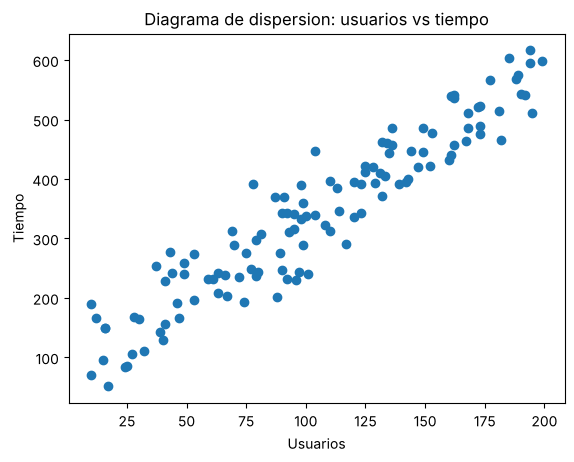

In [3]:
# Criterio L1

plt.scatter(datos_api.usuarios, datos_api.tiempo_ms)
plt.title("Diagrama de dispersion: usuarios vs tiempo")
plt.xlabel("Usuarios")
plt.ylabel("Tiempo")
plt.show()

**Criterio L2 (3.5 %).** Calcule el coeficiente de correlación de Pearson entre `usuarios` y `tiempo_ms` y guárdelo en la variable `r_lineal`.

In [4]:
# Criterio L2
r_lineal = datos_api["usuarios"].corr(datos_api["tiempo_ms"])
print(f"Correlación de Pearson: {r_lineal:.4f}")

Correlación de Pearson: 0.9446


**Criterio L3 (9 %).** Defina la variable predictora `X` (debe ser una tabla de una columna con `usuarios`) y la variable objetivo `y` (`tiempo_ms`). Luego divida los datos en `X_train`, `X_test`, `y_train`, `y_test` usando **20 % para prueba** y `random_state=42`.

In [5]:
# Criterio L3
X = datos_api[["usuarios"]]      # tabla (DataFrame) de UNA columna
y = datos_api["tiempo_ms"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# CELDA DE RESCATE L3. Úsela solo si no pudo completar el criterio L3:
# quite el símbolo # al inicio de cada línea y ejecute la celda.
# idx_prueba = [44, 47, 4, 55, 26, 64, 73, 10, 40, 107, 18, 62, 11, 36, 89, 91, 109, 0,
#      88, 104, 65, 45, 31, 70]
# X_test = datos_api.iloc[idx_prueba, [0]]
# y_test = datos_api.iloc[idx_prueba, 1]
# X_train = datos_api.drop(index=idx_prueba).iloc[:, [0]]
# y_train = datos_api.drop(index=idx_prueba).iloc[:, 1]

**Criterio L4 (9 %).** Cree un modelo de regresión lineal, guárdelo en la variable `modelo_lineal` y entrénelo **solo con los datos de entrenamiento**.

In [7]:
# Criterio L4
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.54]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['usuarios']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,72.56
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


**Criterio L5 (9 %).** Guarde la pendiente del modelo en la variable `pendiente` (como número, no como arreglo) y el intercepto en la variable `intercepto`. Imprima ambos valores.

In [8]:
# Criterio L5
pendiente= modelo_lineal.coef_[0]

intercepto = modelo_lineal.intercept_

print(f"Pendiente: {pendiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")

Pendiente: 2.5410
Intercepto: 72.5578


**Criterio L6 (9 %).** Calcule el R² del modelo sobre el **conjunto de prueba** y guárdelo en la variable `r2_test`.

In [9]:
# Criterio L6
r2_test = modelo_lineal.score(X_test, y_test)

print(f"R2 del conjunto de prueba: {r2_test:.4f}")

R2 del conjunto de prueba: 0.8275


**Criterio L7 (3.5 %).** Use el modelo para estimar el tiempo de respuesta cuando hay **150 usuarios** conectados. Guarde el resultado (un solo número) en la variable `pred_150`.

In [10]:
# Criterio L7
nuevo_usuarios = pd.DataFrame([[150]], columns=["usuarios"])
pred_150 = modelo_lineal.predict(nuevo_usuarios)[0]   # un solo número

print(f"El tiempo estimado con 150 usuarios es de: {pred_150:.2f} ms")

El tiempo estimado con 150 usuarios es de: 453.71 ms


**Criterio L8 (3.5 %).** El jefe de infraestructura quiere usar este modelo para estimar el tiempo de respuesta con **500 usuarios** conectados. ¿Es confiable esa estimación? Responda en máximo tres líneas y justifique.

**Respuesta:** No es confiable. Los datos de entrenamiento solo cubren entre 10 y 200 usuarios, y 500 está muy fuera de ese rango (extrapolación). El modelo asume que la relación sigue siendo lineal, pero con tanta carga el servidor podría saturarse y el tiempo crecer de otra forma.

---
# Ejercicio 2. Regresión logística (50 %)

Una plataforma de cursos en línea quiere detectar a tiempo a los estudiantes que **van a abandonar** un curso, para que un tutor los contacte. Se tienen datos de 400 estudiantes de cursos anteriores:

| Columna | Significado |
|---|---|
| `horas_semana` | Horas promedio por semana conectado a la plataforma |
| `tareas_entregadas` | Porcentaje de tareas entregadas (0 a 100) |
| `dias_sin_ingresar` | Días desde el último ingreso a la plataforma |
| `promedio` | Promedio de calificaciones (0 a 10) |
| `abandona` | **Variable objetivo**: 1 si abandonó el curso, 0 si lo terminó |

In [11]:
# Generación de datos. NO MODIFICAR.
rng = np.random.default_rng(7)
n = 400
horas = np.round(rng.uniform(0, 15, n), 1)
tareas = np.round(rng.uniform(20, 100, n), 0)
dias = rng.integers(0, 31, n)
promedio = np.round(np.clip(rng.normal(7, 1.5, n), 0, 10), 1)
z = 1.5 - 0.25 * horas - 0.035 * tareas + 0.12 * dias - 0.25 * promedio
abandona = (rng.uniform(0, 1, n) < 1 / (1 + np.exp(-z))).astype(int)
estudiantes = pd.DataFrame({
    "horas_semana": horas,
    "tareas_entregadas": tareas,
    "dias_sin_ingresar": dias,
    "promedio": promedio,
    "abandona": abandona,
})
estudiantes.head()

,horas_semana,tareas_entregadas,dias_sin_ingresar,promedio,abandona
0,9.4,46.0,19,4.6,0
1,13.5,95.0,30,7.0,0
2,11.6,32.0,18,7.7,0
3,3.4,61.0,4,8.5,0
4,4.5,27.0,28,6.8,1


**Criterio G1 (9 %).** Defina `X` con las cuatro características y `y` con la variable objetivo. Divida los datos en `X_train`, `X_test`, `y_train`, `y_test` usando **25 % para prueba** y `random_state=16`.

In [12]:
# Criterio G1
X = estudiantes.drop(columns="abandona")
y = estudiantes["abandona"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

In [13]:
# CELDA DE RESCATE G1. Úsela solo si no pudo completar el criterio G1:
# quite el símbolo # al inicio de cada línea y ejecute la celda.
# idx_prueba = [330, 215, 305, 326, 26, 309, 168, 249, 97, 102, 106, 190, 147, 306, 30,
#     387, 244, 235, 373, 142, 295, 11, 88, 83, 189, 363, 346, 103, 339, 288, 194, 276,
#     315, 0, 322, 84, 382, 35, 261, 136, 332, 157, 126, 250, 340, 64, 280, 289, 70,
#     298, 323, 108, 264, 129, 221, 396, 255, 57, 385, 54, 247, 246, 361, 335, 132,
#     191, 53, 1, 286, 76, 105, 71, 224, 310, 372, 257, 281, 316, 222, 51, 38, 135, 59,
#     308, 29, 174, 237, 291, 320, 175, 140, 242, 392, 199, 164, 32, 200, 331, 18, 133]
# X_test = estudiantes.iloc[idx_prueba, :4]
# y_test = estudiantes.iloc[idx_prueba, 4]
# X_train = estudiantes.drop(index=idx_prueba).iloc[:, :4]
# y_train = estudiantes.drop(index=idx_prueba).iloc[:, 4]

**Criterio G2 (9 %).** Cree un modelo de regresión logística con `random_state=16` y `max_iter=5000`, guárdelo en `modelo_log` y entrénelo con los datos de entrenamiento. Luego obtenga las predicciones de clase para el conjunto de prueba y guárdelas en `y_pred`.

In [14]:
# Criterio G2
modelo_log=LogisticRegression(random_state=16, max_iter=5000)

modelo_log.fit(X_train, y_train)
y_pred = modelo_log.predict(X_test)

In [15]:
# CELDA DE RESCATE G2. Úsela solo si no pudo completar el criterio G2:
# quite el símbolo # al inicio de cada línea y ejecute la celda.
# Le entrega un modelo ya entrenado y sus predicciones sobre el conjunto de prueba.
# modelo_log = LogisticRegression(random_state=16, max_iter=5000)
# modelo_log.classes_ = np.array([0, 1])
# modelo_log.coef_ = np.array([[-0.269738, -0.030345, 0.103421, -0.203800]])
# modelo_log.intercept_ = np.array([1.482806])
# modelo_log.n_features_in_ = 4
# modelo_log.feature_names_in_ = np.array(["horas_semana", "tareas_entregadas",
#                                          "dias_sin_ingresar", "promedio"], dtype=object)
# y_pred = modelo_log.predict(X_test)

**Criterio G3 (9 %).** Construya la matriz de confusión del modelo sobre el conjunto de prueba, guárdela en la variable `matriz` e imprímala.

In [16]:
# Criterio G3
matriz = confusion_matrix(y_test, y_pred)
print(matriz)

[[80  1]
 [13  6]]


**Criterio G4 (3.5 %).** Obtenga, para cada estudiante del conjunto de prueba, la **probabilidad de abandonar** (clase 1) y guárdela en la variable `proba` (un arreglo de una dimensión con una probabilidad por estudiante).

In [17]:
# Criterio G4
proba = modelo_log.predict_proba(X_test)[:, 1]   # solo la columna de la clase 1, arreglo 1D
print(proba[:10])

[0.23299503 0.20330182 0.35801366 0.25889705 0.21595666 0.04950472
 0.16358328 0.03612177 0.2504239  0.03261771]


**Criterio G5 (9 %).** Calcule el **AUC** (área bajo la curva ROC) del modelo sobre el conjunto de prueba y guárdelo en la variable `auc`.

In [18]:
# Criterio G5
auc = roc_auc_score(y_test, proba)   # se usan las PROBABILIDADES, no las clases predichas
print(f"AUC: {auc:.4f}")

AUC: 0.8447


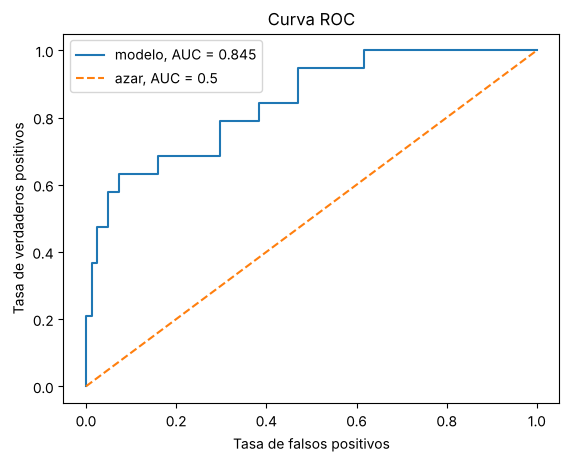

In [19]:
# Curva ROC. Esta celda ya está resuelta y no se califica. NO MODIFICAR.
# Se dibuja solo si G4 y G5 están completos.
try:
    fpr, tpr, umbrales = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"modelo, AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="azar, AUC = 0.5")
    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("Curva ROC")
    plt.legend()
    plt.show()
except Exception:
    print("No se puede dibujar la curva ROC: complete primero los criterios G1, G2, G4 y G5.")

**Criterio G6 (3.5 %).** ¿Qué indica el valor de AUC que obtuvo sobre la capacidad del modelo para distinguir entre estudiantes que abandonan y estudiantes que terminan el curso? Compárelo con el valor que tendría un modelo que clasifica al azar. Responda en máximo tres líneas.

**Respuesta:** Un AUC de 0.84 indica que el modelo distingue bastante bien entre quienes abandonan y quienes terminan: en cerca del 84 % de los pares (un abandonador y un no abandonador) asigna mayor probabilidad al que abandona. Un modelo al azar tendría AUC = 0.5, así que el modelo es claramente mejor que adivinar.

**Clasificar a una estudiante nueva.** Esta semana se inscribió una estudiante con estos datos: se conecta **1 hora** por semana, ha entregado el **30 %** de las tareas, lleva **28 días** sin ingresar y su promedio es **5.0**. Use el modelo entrenado para clasificarla

**Criterio G7 (3.5 %).** Construya una tabla de una fila con los datos de la estudiante, con las mismas columnas y en el mismo orden que `X_train`, y guárdela en la variable `nueva`. Use el modelo para predecir su clase, guarde el resultado (0 o 1) en `clase_nueva` e imprima el mensaje `Predicción: abandona` o `Predicción: no abandona` según corresponda.

In [20]:
# Criterio G7
nueva = pd.DataFrame([[1, 30, 28, 5.0]], columns=X_train.columns)
clase_nueva = modelo_log.predict(nueva)[0]

if clase_nueva == 1:
    print("Predicción: abandona")
else:
    print("Predicción: no abandona")

Predicción: abandona


**Criterio G8 (3.5 %).** Calcule la probabilidad de que la estudiante **abandone** el curso, guárdela en la variable `proba_nueva` (un solo número) e imprima el mensaje `Probabilidad de abandono: ` seguido del valor con tres decimales.

In [21]:
# Criterio G8
proba_nueva = modelo_log.predict_proba(nueva)[0, 1]   # un solo número
print(f"Probabilidad de abandono: {proba_nueva:.3f}")

Probabilidad de abandono: 0.898
